In [1]:
# Imports and reproducibility
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
TARGET = "Output"

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# Dataset source used by the forwarded notebook
DATA_URL = "https://raw.githubusercontent.com/abhiii1801/AgriScan/main/soil_data.csv"
LOCAL_FILE = Path("soil_data.csv")

try:
    df = pd.read_csv(DATA_URL)
    source_used = "GitHub URL"
except Exception as e:
    if LOCAL_FILE.exists():
        df = pd.read_csv(LOCAL_FILE)
        source_used = "Local soil_data.csv"
    else:
        raise RuntimeError(
            "Could not load the dataset from GitHub, and soil_data.csv was not found locally. "
            "Download soil_data.csv from the project's repository and place it beside this notebook."
        ) from e

print(f"Dataset source: {source_used}")
print(f"Dataset shape: {df.shape}")
print("\nFirst five rows:")
display(df.head())

Dataset source: GitHub URL
Dataset shape: (880, 13)

First five rows:


,N,P,K,pH,EC,OC,S,Zn,Fe,Cu,Mn,B,Output
0,138,8.6,560,7.46,0.62,0.70,5.9,0.24,0.31,0.77,8.71,0.11,0
1,213,7.5,338,7.62,0.75,1.06,25.4,0.30,0.86,1.54,2.89,2.29,0
2,163,9.6,718,7.59,0.51,1.11,14.3,0.30,0.86,1.57,2.70,2.03,0
3,157,6.8,475,7.64,0.58,0.94,26.0,0.34,0.54,1.53,2.65,1.82,0
4,270,9.9,444,7.63,0.40,0.86,11.8,0.25,0.76,1.69,2.43,2.26,1


In [3]:
# Basic dataset audit
print("Shape:", df.shape)
print("Number of input features:", df.shape[1] - 1)
print("Target column:", TARGET)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Target classes:", sorted(df[TARGET].unique()))

print("\nFeature columns:")
print(df.drop(columns=[TARGET]).columns.tolist())

print("\nClass counts:")
print(df[TARGET].value_counts().sort_index())

Shape: (880, 13)
Number of input features: 12
Target column: Output
Missing values: 0
Duplicate rows: 0
Target classes: [np.int64(0), np.int64(1), np.int64(2)]

Feature columns:
['N', 'P', 'K', 'pH', 'EC', 'OC', 'S', 'Zn', 'Fe', 'Cu', 'Mn', 'B']

Class counts:
Output
0    401
1    440
2     39
Name: count, dtype: int64


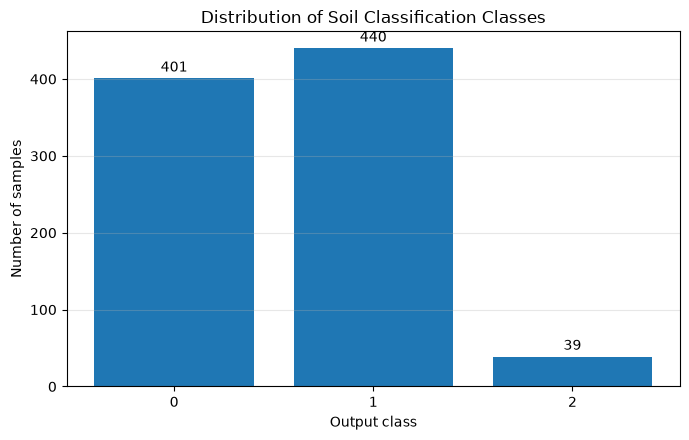

In [5]:
# Graph 1: Target/class distribution
class_counts = df[TARGET].value_counts().sort_index()

plt.figure(figsize=(7, 4.5))
bars = plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Output class")
plt.ylabel("Number of samples")
plt.title("Distribution of Soil Classification Classes")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + max(class_counts.values) * 0.01,
             str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()


In [6]:
# Separate features and target
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

# First hold out the final test set: 20%
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Split the remaining 80% into 60% train and 20% validation overall
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

# Median imputation learned ONLY from training data
train_medians = X_train.median(numeric_only=True)
X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print(f"Training samples:   {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Validation samples: {len(X_val)} ({len(X_val)/len(X):.0%})")
print(f"Test samples:       {len(X_test)} ({len(X_test)/len(X):.0%})")


Training samples:   528 (60%)
Validation samples: 176 (20%)
Test samples:       176 (20%)


In [7]:
# Complexity levels to investigate
DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10, None]

results = []

for depth in DEPTHS:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE,
    )
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    results.append({
        "Max Depth": "Unpruned" if depth is None else depth,
        "Depth Value": np.nan if depth is None else depth,
        "Actual Tree Depth": model.get_depth(),
        "Nodes": model.tree_.node_count,
        "Leaves": model.get_n_leaves(),
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Train F1": f1_score(y_train, train_pred, average="weighted"),
        "Validation F1": f1_score(y_val, val_pred, average="weighted"),
    })

results_df = pd.DataFrame(results)
results_df["Accuracy Gap"] = (
    results_df["Train Accuracy"] - results_df["Validation Accuracy"]
)
results_df["F1 Gap"] = (
    results_df["Train F1"] - results_df["Validation F1"]
)

print("Performance and complexity across tree depths:")
display(
    results_df[
        [
            "Max Depth", "Actual Tree Depth", "Nodes", "Leaves",
            "Train Accuracy", "Validation Accuracy",
            "Train F1", "Validation F1",
            "Accuracy Gap", "F1 Gap"
        ]
    ].round(3)
)


Performance and complexity across tree depths:


,Max Depth,Actual Tree Depth,Nodes,Leaves,Train Accuracy,Validation Accuracy,Train F1,Validation F1,Accuracy Gap,F1 Gap
0,1,1,3,2,0.867,0.892,0.847,0.871,-0.025,-0.024
1,2,2,7,4,0.898,0.898,0.878,0.877,0.000,0.001
2,3,3,15,8,0.934,0.926,0.934,0.928,0.008,0.007
3,4,4,25,13,0.947,0.909,0.946,0.909,0.038,0.037
4,5,5,41,21,0.970,0.892,0.969,0.888,0.078,0.082
5,6,6,57,29,0.981,0.892,0.981,0.889,0.089,0.092
6,8,8,77,39,0.994,0.881,0.994,0.881,0.114,0.113
7,10,9,83,42,1.000,0.881,1.000,0.881,0.119,0.119
8,Unpruned,9,83,42,1.000,0.881,1.000,0.881,0.119,0.119


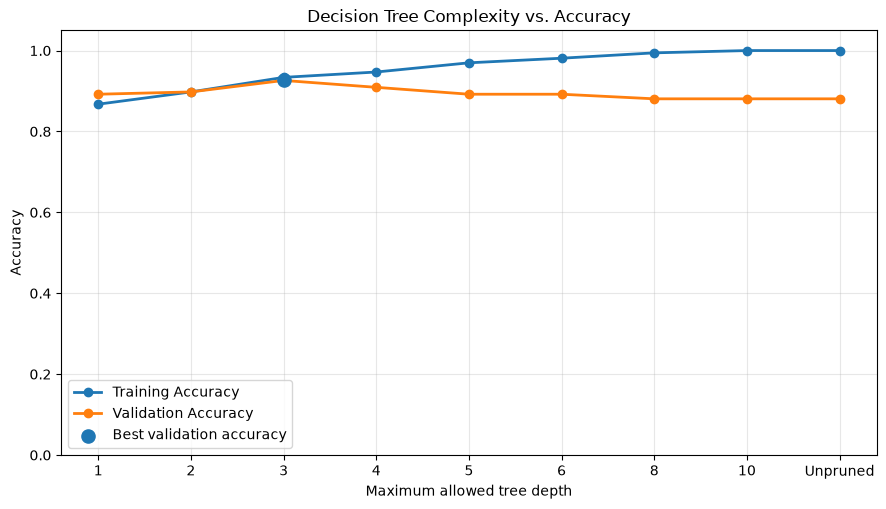

In [8]:
# Graph 2: Accuracy comparison
labels = results_df["Max Depth"].astype(str)
x = np.arange(len(labels))

plt.figure(figsize=(9, 5.2))
plt.plot(x, results_df["Train Accuracy"], marker="o", linewidth=2, label="Training Accuracy")
plt.plot(x, results_df["Validation Accuracy"], marker="o", linewidth=2, label="Validation Accuracy")

best_idx = results_df["Validation Accuracy"].idxmax()
plt.scatter(
    [best_idx],
    [results_df.loc[best_idx, "Validation Accuracy"]],
    s=90,
    zorder=5,
    label="Best validation accuracy",
)

plt.xticks(x, labels)
plt.ylim(0, 1.05)
plt.xlabel("Maximum allowed tree depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Complexity vs. Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


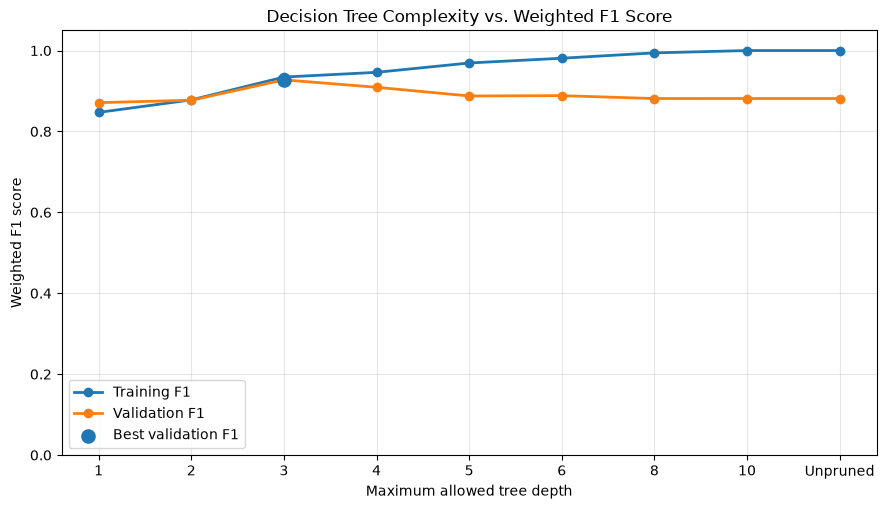

In [9]:
# Graph 3: F1 comparison
plt.figure(figsize=(9, 5.2))
plt.plot(x, results_df["Train F1"], marker="o", linewidth=2, label="Training F1")
plt.plot(x, results_df["Validation F1"], marker="o", linewidth=2, label="Validation F1")

best_f1_idx = results_df["Validation F1"].idxmax()
plt.scatter(
    [best_f1_idx],
    [results_df.loc[best_f1_idx, "Validation F1"]],
    s=90,
    zorder=5,
    label="Best validation F1",
)

plt.xticks(x, labels)
plt.ylim(0, 1.05)
plt.xlabel("Maximum allowed tree depth")
plt.ylabel("Weighted F1 score")
plt.title("Decision Tree Complexity vs. Weighted F1 Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


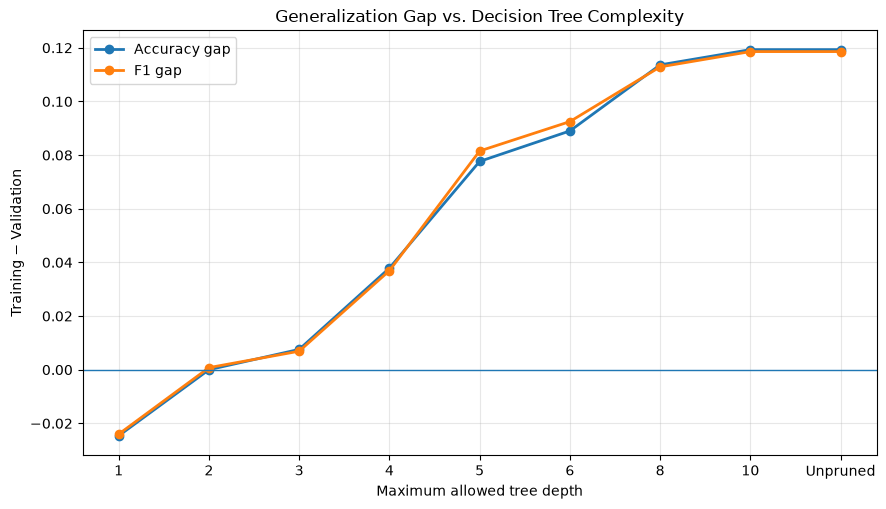

In [10]:
# Graph 4: Generalization gaps
plt.figure(figsize=(9, 5.2))
plt.plot(x, results_df["Accuracy Gap"], marker="o", linewidth=2, label="Accuracy gap")
plt.plot(x, results_df["F1 Gap"], marker="o", linewidth=2, label="F1 gap")

plt.axhline(0, linewidth=1)
plt.xticks(x, labels)
plt.xlabel("Maximum allowed tree depth")
plt.ylabel("Training − Validation")
plt.title("Generalization Gap vs. Decision Tree Complexity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

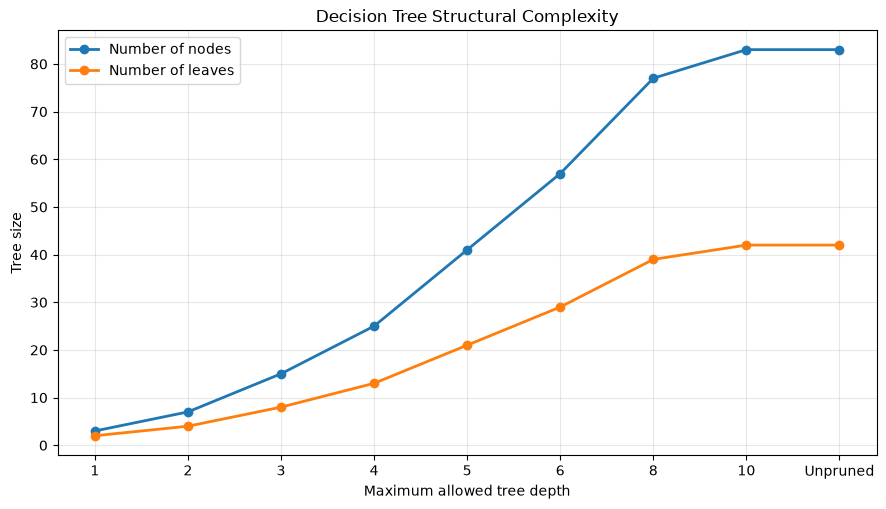

In [11]:
# Graph 5: Structural complexity
plt.figure(figsize=(9, 5.2))
plt.plot(x, results_df["Nodes"], marker="o", linewidth=2, label="Number of nodes")
plt.plot(x, results_df["Leaves"], marker="o", linewidth=2, label="Number of leaves")

plt.xticks(x, labels)
plt.xlabel("Maximum allowed tree depth")
plt.ylabel("Tree size")
plt.title("Decision Tree Structural Complexity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
# Select best complexity using validation performance only
best_row = (
    results_df
    .sort_values(
        by=["Validation F1", "Validation Accuracy"],
        ascending=False,
    )
    .iloc[0]
)

best_label = best_row["Max Depth"]
best_depth = None if best_label == "Unpruned" else int(best_label)

print("Selected model based on validation performance")
print("----------------------------------------------")
print("Best max_depth:", best_label)
print("Validation Accuracy:", round(best_row["Validation Accuracy"], 3))
print("Validation F1:", round(best_row["Validation F1"], 3))


Selected model based on validation performance
----------------------------------------------
Best max_depth: 3
Validation Accuracy: 0.926
Validation F1: 0.928


In [14]:
# Combine train + validation data for the final fit
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)

final_model = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=RANDOM_STATE,
)
final_model.fit(X_train_full, y_train_full)

final_pred = final_model.predict(X_test)

final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(y_test, final_pred, average="weighted", zero_division=0)
final_recall = recall_score(y_test, final_pred, average="weighted", zero_division=0)
final_f1 = f1_score(y_test, final_pred, average="weighted")

final_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "Weighted F1"],
    "Test Score": [final_accuracy, final_precision, final_recall, final_f1],
})

display(final_metrics.round(3))

print("Actual final tree depth:", final_model.get_depth())
print("Final tree nodes:", final_model.tree_.node_count)
print("Final tree leaves:", final_model.get_n_leaves())

,Metric,Test Score
0,Accuracy,0.869
1,Precision,0.877
2,Recall,0.869
3,Weighted F1,0.873


Actual final tree depth: 3
Final tree nodes: 15
Final tree leaves: 8


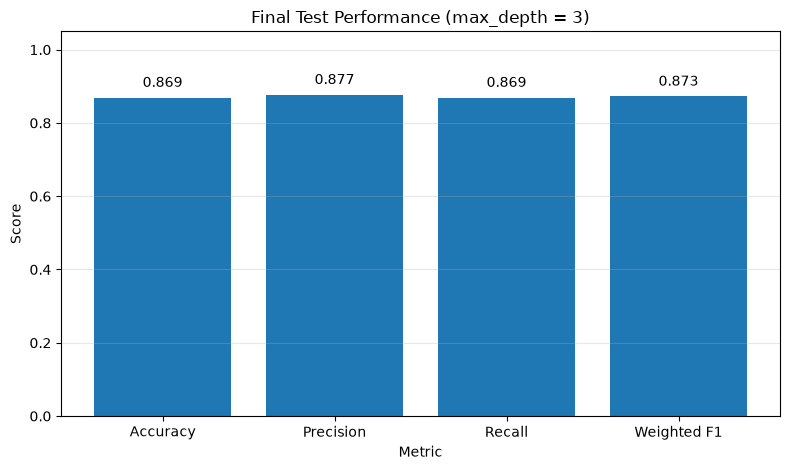

In [15]:
# Graph 6: Final test metrics
plt.figure(figsize=(8, 4.8))
bars = plt.bar(final_metrics["Metric"], final_metrics["Test Score"])
plt.ylim(0, 1.05)
plt.xlabel("Metric")
plt.ylabel("Score")
plt.title(f"Final Test Performance (max_depth = {best_label})")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, final_metrics["Test Score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()


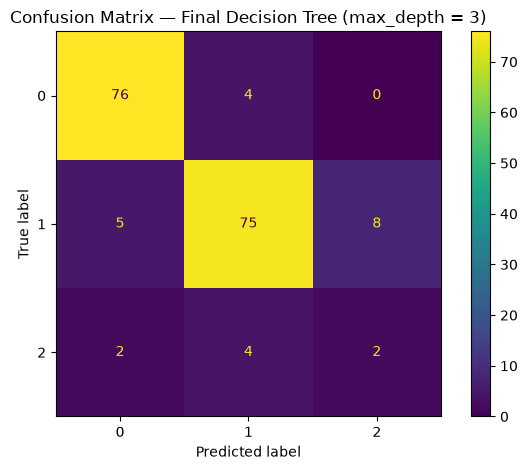

In [16]:
# Graph 7: Final confusion matrix
cm = confusion_matrix(y_test, final_pred, labels=sorted(y.unique()))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sorted(y.unique()),
)
disp.plot(values_format="d")
plt.title(f"Confusion Matrix — Final Decision Tree (max_depth = {best_label})")
plt.tight_layout()
plt.show()


In [17]:
# Automatically generate a concise, data-driven conclusion from the experiment
best_validation_f1 = best_row["Validation F1"]
lowest_depth_row = results_df.iloc[0]
highest_complexity_row = results_df.iloc[-1]

print("FINAL INTERPRETATION")
print("====================")
print(
    f"The best validation performance was obtained at max_depth = {best_label}, "
    f"with validation accuracy {best_row['Validation Accuracy']:.3f} "
    f"and weighted F1 {best_validation_f1:.3f}."
)
print(
    f"At the highest tested complexity ({highest_complexity_row['Max Depth']}), "
    f"training accuracy was {highest_complexity_row['Train Accuracy']:.3f}, "
    f"while validation accuracy was {highest_complexity_row['Validation Accuracy']:.3f}."
)
print(
    f"The corresponding accuracy generalization gap was "
    f"{highest_complexity_row['Accuracy Gap']:.3f}."
)
print(
    "This comparison shows why increasing model complexity can improve training fit "
    "while eventually reducing performance on unseen data."
)


FINAL INTERPRETATION
The best validation performance was obtained at max_depth = 3, with validation accuracy 0.926 and weighted F1 0.928.
At the highest tested complexity (Unpruned), training accuracy was 1.000, while validation accuracy was 0.881.
The corresponding accuracy generalization gap was 0.119.
This comparison shows why increasing model complexity can improve training fit while eventually reducing performance on unseen data.
